# DATA 607 - API WALKTHROUGH - NBA API


#### A video guide to accessing NBA data through the NBA_API python package

### Presented by: Kailot Harris;   Date: 2026/10/13

* * *

## 2025-2026 Playoff Summary

First, import packages and data objects from API

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from nba_api.stats.endpoints import leaguegamelog
from nba_api.stats.endpoints import shotchartdetail
from nba_api.stats.static import players

Seccond, pull data for 2025-2026 playoffs, summarize first 10 playoff games

In [2]:
playoff_games = leaguegamelog.LeagueGameLog(
    season='2025-26',               # Use a completed season for real stats
    season_type_all_star='Playoffs' # Filter strictly for PLAYOFF games
)

# Convert to a clean Pandas DataFrame
df = playoff_games.get_data_frames()[0]

# Filter to WINNERS only (removes duplicate rows for the same game)
winners_df = df[df['WL'] == 'W'].copy()
winners_df['GAME_DATE'] = pd.to_datetime(winners_df['GAME_DATE'])

# Dynamically find the two teams in the Finals
# The very last game played on the calendar is the Finals clincher!
latest_game = winners_df.sort_values('GAME_DATE', ascending=False).iloc[0]
teams_in_finals = latest_game['MATCHUP'].replace('@', 'vs.').split(' vs. ')
team_a, team_b = teams_in_finals[0].strip(), teams_in_finals[1].strip()

# Filter for only games between the two Finals teams
finals_df = winners_df[
    winners_df['MATCHUP'].str.contains(team_a) & winners_df['MATCHUP'].str.contains(team_b)
].sort_values('GAME_DATE').reset_index(drop=True)

# Add a "Game #" label (Game 1, Game 2, etc.)
finals_df['GAME'] = [f"Game {i+1}" for i in range(len(finals_df))]


# Display the final summary table
finals_summary = finals_df[['GAME', 'GAME_DATE', 'MATCHUP', 'PTS', 'PLUS_MINUS']]
print(finals_summary.to_string(index=False))

  GAME  GAME_DATE     MATCHUP  PTS  PLUS_MINUS
Game 1 2026-06-03   NYK @ SAS  105          10
Game 2 2026-06-05   NYK @ SAS  105           1
Game 3 2026-06-08   SAS @ NYK  115           4
Game 4 2026-06-10 NYK vs. SAS  107           1
Game 5 2026-06-13   NYK @ SAS   94           4


## Steph Curry's 2015-2016 Season

Pull Curry's shot data from 2015-2016 season, plot x-y coordinates and make/miss dots

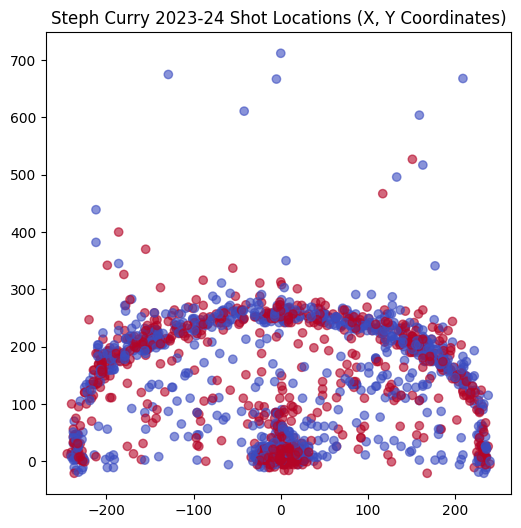

In [ ]:
# Steph Curry's Player ID: 201939
shots = shotchartdetail.ShotChartDetail(
    team_id=0,
    player_id=201939,
    season_nullable='2015-16',
    context_measure_simple='FGA'
)

df_shots = shots.get_data_frames()[0]

# Quick scatter plot of shot locations
plt.figure(figsize=(6, 6))
plt.scatter(df_shots['LOC_X'], df_shots['LOC_Y'], c=df_shots['SHOT_MADE_FLAG'], cmap='coolwarm', alpha=0.6)
plt.title("Steph Curry 2015-16 Shot Locations (X, Y Coordinates)")
plt.show()

## Active Players

Fetch and display list of active players

In [4]:
# Fetch all historical and active players locally
all_players = players.get_players()
df_players = pd.DataFrame(all_players)

# Filter for active players only
active_players = df_players[df_players['is_active'] == True]

print(f"Total active players in dataset: {len(active_players)}")
print(active_players[['id', 'full_name', ]].head(15))

Total active players in dataset: 530
          id                 full_name
10   1630173          Precious Achiuwa
22    203500              Steven Adams
24   1628389               Bam Adebayo
29   1630534              Ochai Agbaji
41   1630583              Santi Aldama
52   1641725            Trey Alexander
55   1629638  Nickeil Alexander-Walker
59   1628960             Grayson Allen
60   1628386             Jarrett Allen
77   1630631             Jose Alvarado
98    203937             Kyle Anderson
113  1630828        Alex Antetokounmpo
114   203507     Giannis Antetokounmpo
116   203648    Thanasis Antetokounmpo
118  1630175              Cole Anthony
